# Agent training results

Run all cells from the repository root or `src/experiments/visual-augmentation-simple/`.
Set `DATA_DIR` to select a different agent output folder. Each run uses
`seed-N/vector/metrics.csv` or `seed-N/combined/metrics.csv`.

Return is the mean out-of-distribution evaluation return. Episode is the
number of completed training episodes at evaluation. Wall time is cumulative
agent training seconds for rollout collection and PPO updates. The plots use
the recorded evaluation points with no smoothing. PPO updates count optimizer
steps completed by each evaluation checkpoint, including the update after
the rollout ending at that episode.

Episode averages use the available seeds at each episode. Wall-time and PPO-update averages
interpolate each seed linearly over the recorded values in the shared range.
If an update count repeats, interpolation uses its last evaluation. Seeds
have equal weight.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Load evaluation records from each seed and modality.
EXPERIMENT = Path("src/experiments/visual-augmentation-simple")
OUTPUT = Path("outputs/visual-augmentation-simple/agents")
DATA_DIR = EXPERIMENT / OUTPUT if (EXPERIMENT / OUTPUT).is_dir() else OUTPUT
PPO_UPDATES = "PPO updates"
TAGS = {
    "eval/return_ood": "Return",
    "compute/agent_training_seconds": "Wall time (seconds)",
    "compute/agent_updates": PPO_UPDATES,
}
METRICS = ["Return", "Episode", "Wall time (seconds)", PPO_UPDATES]
runs = {}
for path in sorted(DATA_DIR.glob("seed-*/*/metrics.csv")):
    records = pd.read_csv(path).rename(columns={"step": "Episode"})
    records = records.loc[records.metric.isin(TAGS)]
    values = records.pivot(index="Episode", columns="metric", values="value")
    runs[path.parent.parent.name, path.parent.name] = (
        values.rename(columns=TAGS).reset_index().reindex(columns=METRICS)
    )
if not runs:
    raise FileNotFoundError(f"No agent metrics.csv files found under {DATA_DIR}")
print(f"Loaded {len(runs)} agent runs from {DATA_DIR.resolve()}")

Loaded 6 agent runs from C:\Users\jason\Documents\Code Projects\wam-comparison\src\experiments\visual-augmentation-simple\outputs\visual-augmentation-simple\agents


In [2]:
# Average episodes directly and interpolate on the other axes.
def mean_curve(curves, axis):
    if axis == "Episode":
        return pd.concat(curves).groupby(axis, as_index=False).mean()
    curves = [
        run.drop_duplicates(axis, keep="last").sort_values(axis) for run in curves
    ]
    grid = np.unique(np.concatenate([run[axis] for run in curves]))
    values = [
        [
            np.interp(grid, run[axis], run[metric], left=np.nan, right=np.nan)
            for metric in METRICS
        ]
        for run in curves
    ]
    return pd.DataFrame(np.mean(values, axis=0).T, columns=METRICS).dropna(
        subset=["Return", "Episode", "Wall time (seconds)", axis]
    )


def plot_metrics(axis, average):
    fig, axes = plt.subplots(
        1,
        len(METRICS),
        sharex=True,
        figsize=(5 * len(METRICS), 3.3),
        layout="constrained",
    )
    seeds = sorted({seed for seed, _ in runs})
    seed_colors = {seed: plt.get_cmap("tab20")(i % 20) for i, seed in enumerate(seeds)}

    for modality, style, color in (
        ("vector", ".-", "tab:blue"),
        ("combined", ".:", "tab:orange"),
    ):
        curves = {
            seed: run.dropna(subset=[axis])
            for (seed, name), run in runs.items()
            if name == modality
        }
        curves = {seed: run for seed, run in curves.items() if not run.empty}
        if average and curves:
            curves = {None: mean_curve(curves.values(), axis)}
        for seed, run in curves.items():
            label = modality if average else f"{modality} / {seed}"
            line_color = color if average else seed_colors[seed]
            for ax, metric in zip(axes, METRICS):
                ax.plot(run[axis], run[metric], style, color=line_color, label=label)

    for ax, metric in zip(axes, METRICS):
        ax.set(title=metric, xlabel=axis)
        ax.grid(alpha=0.25)
        ax.legend(loc="best", fontsize="small")
    fig.suptitle("Mean across seeds" if average else "Individual seeds")
    plt.show()

## 1. All metrics against episode, averaged over seeds

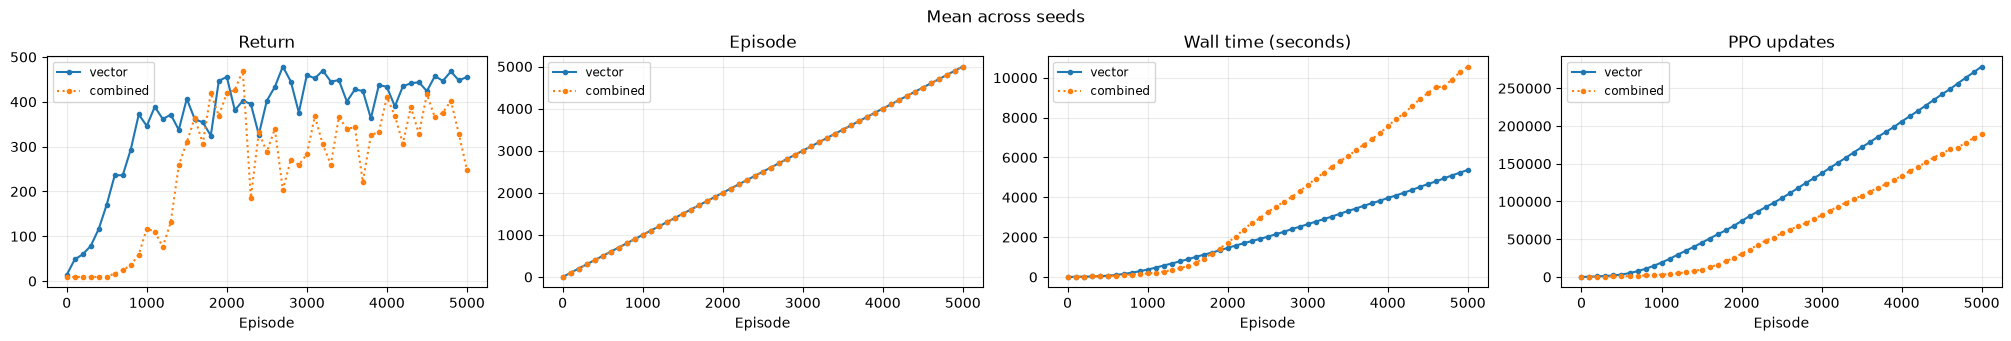

In [3]:
plot_metrics("Episode", average=True)

## 2. All metrics against wall time, averaged over seeds

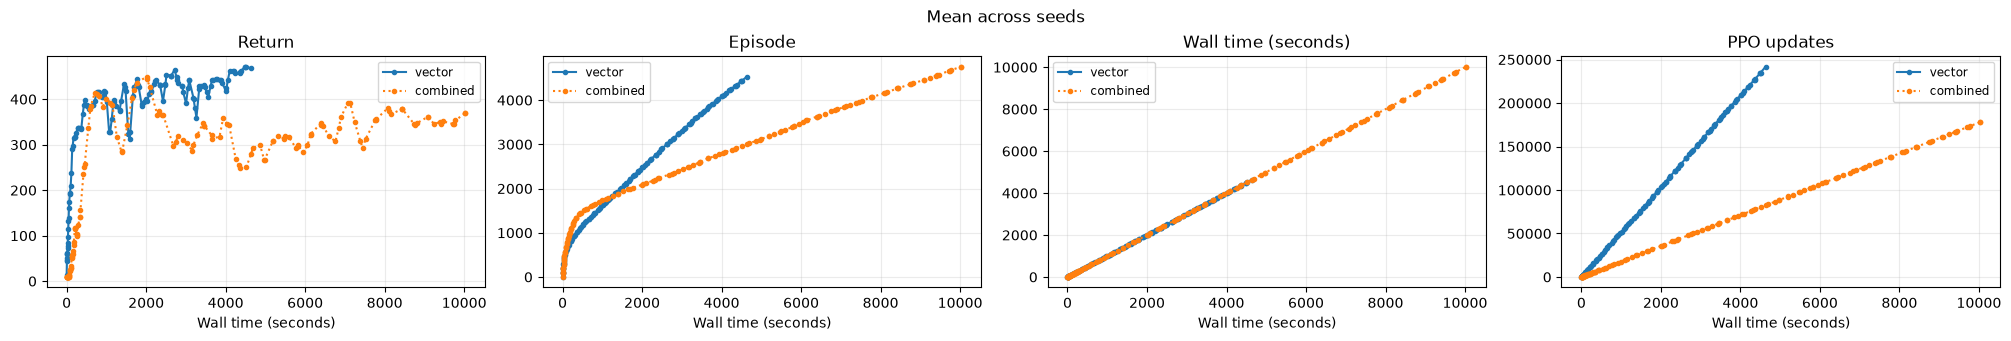

In [4]:
plot_metrics("Wall time (seconds)", average=True)

## 3. All metrics against episode, one trace per seed

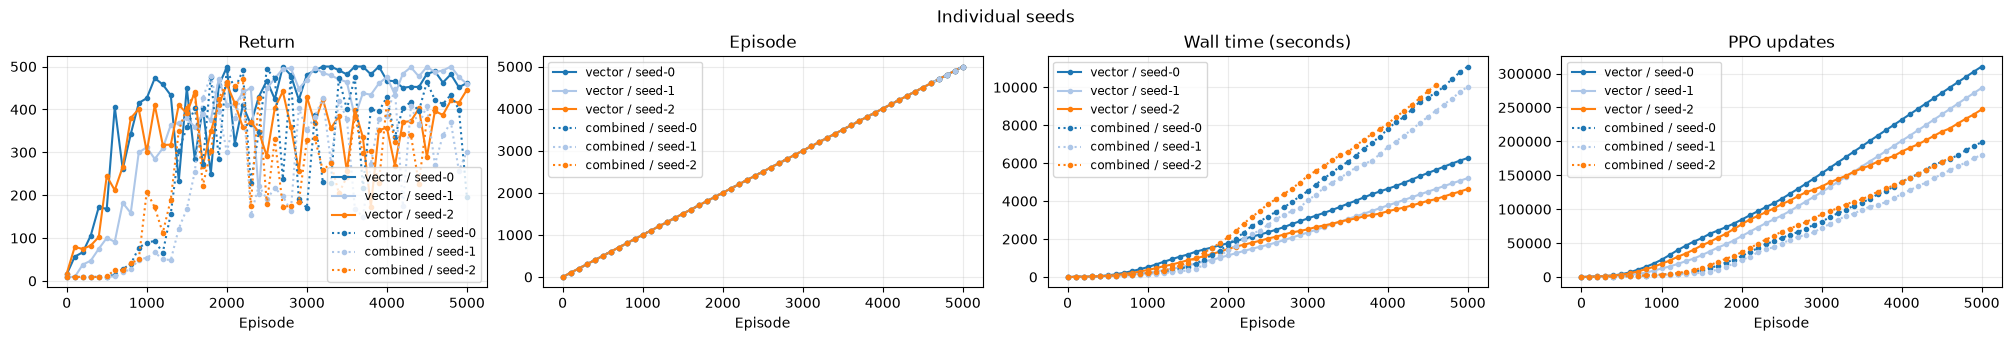

In [5]:
plot_metrics("Episode", average=False)

## 4. All metrics against wall time, one trace per seed

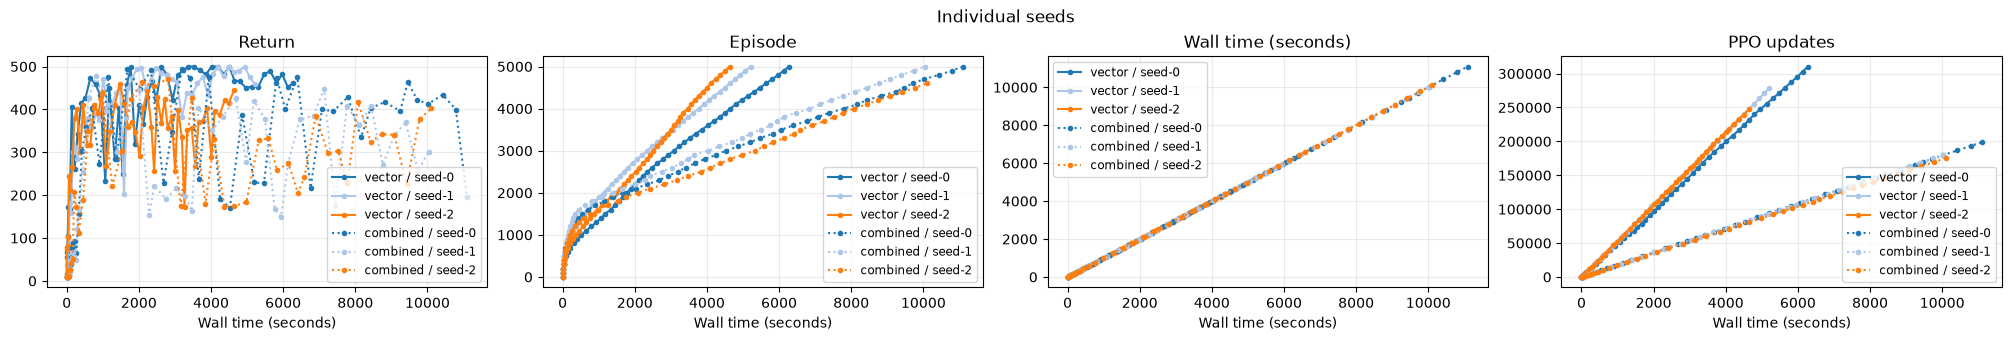

In [6]:
plot_metrics("Wall time (seconds)", average=False)

## 5. Mean across seeds against PPO updates

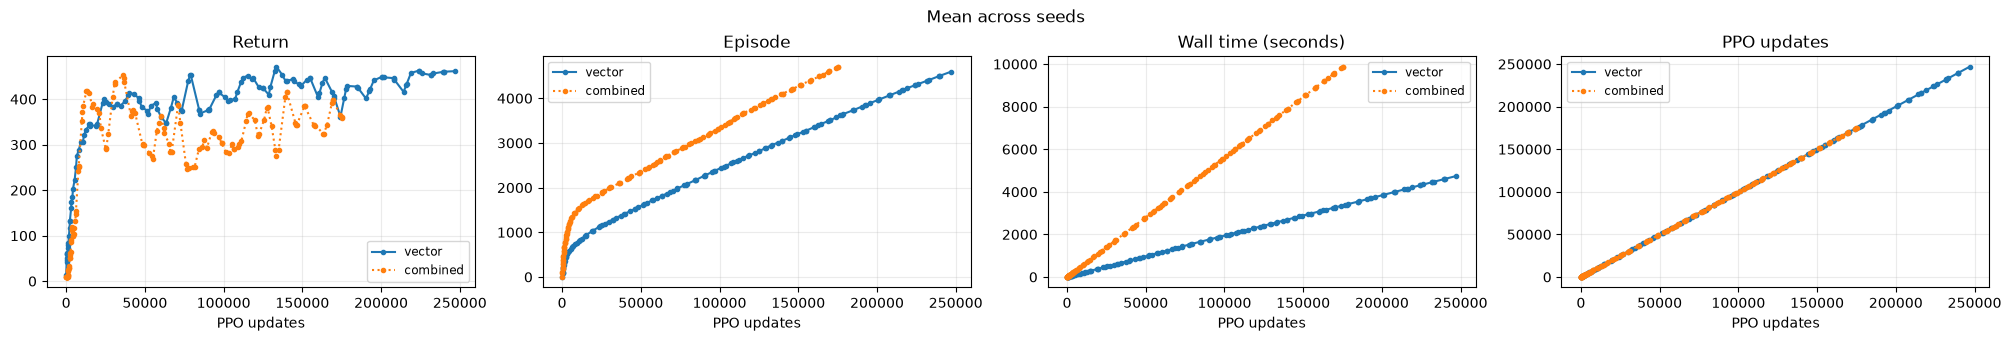

In [7]:
plot_metrics(PPO_UPDATES, average=True) 

## 6. Individual seeds against PPO updates

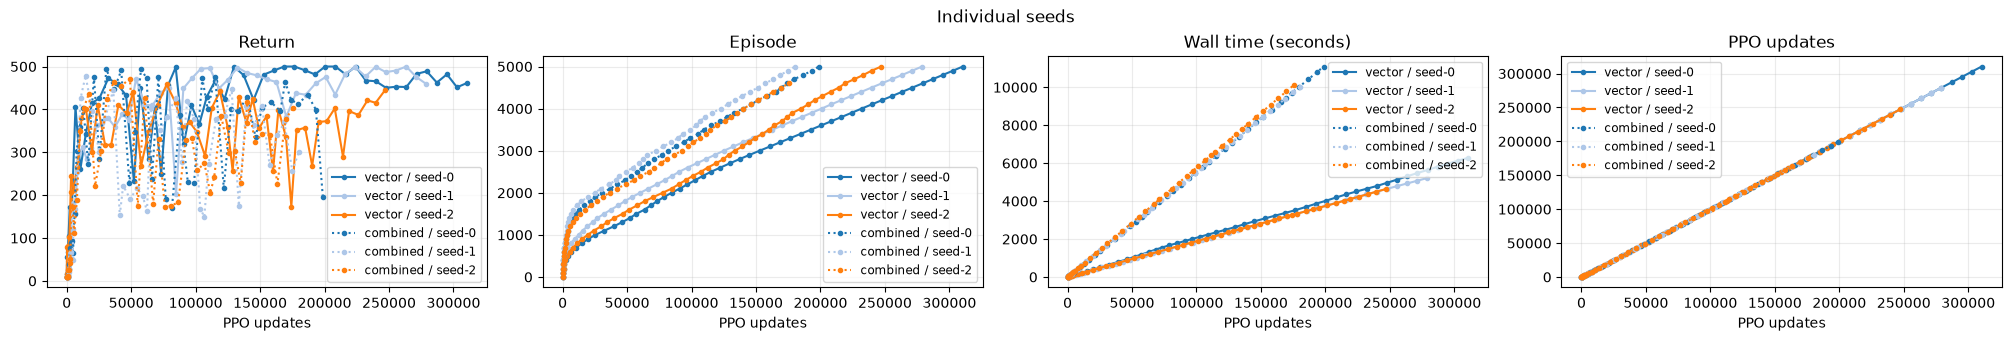

In [8]:
plot_metrics(PPO_UPDATES, average=False)